# Assignment #4


# 1. Basics of Geostatistics (25 pts)

Each observation of an environmental variable in space $z(\mathbf{x})$ can be interpreted as a single realization of a random variable $Z(\mathbf{x})$. Where $\mathbf{x}$ denotes the position in space of the observation. In a given finite region there can be an infinite number of locations $\mathbf{x}$ and thus an infinite number of random variables $Z(\mathbf{x})$. The set of all these random variables $Z(\mathbf{x})$ constitutes a random process. For the remainder of this problem assume $Z_i = Z(\mathbf{x})$ and $z_i = z(\mathbf{x})$.

A. Explain the difference between $z_i$ and $Z_i$.

B. Based on the lectures, define $Z^*$ and $Z_0$. Explain the difference between the two. 

C. Describe the meaning of $\text{Cov}(Z_i,Z_j)$, $\text{Cov}(Z_i,Z_0)$, $\text{Var}(Z_0)$.

D. The Simple Kriging system is given by $\Sigma \mathbf{w} = \mathbf{c}$. Explain each term in that equation.

E. Once $\mathbf{w}$ is computed, how can it be used to estimate $z^*$? 

F. What is second-order stationarity?

G. Assuming second-order stationarity, if we are interested in the covariance between $Z_i$ and $Z_j$, why do we concern ourselves with the semivariogram?

H. Starting from the definition of covariance, derive the relationship between covariance and semivariogram. 

A: $Z_i$ is a random variable. That is, before a point in space is measured, there is a range of values that it, $Z_i$, could take, with the probability of any one of these values occurring being governed by some distribution. $z_i$, on the other hand, is the actual, true realization of $Z_i$ when measured with a scientific instrument.  
B: $Z*$ is a linear estimator, or the thing that estimates $Z_0$. $Z*$ is the linear combination of the random variables (n # of $Z_i$s) at the sampled locations in a study. $Z_0$ is the random variable that we want to estimate and do not yet know.  
C: $Cov(Z_i,Z_j)$ denotes the covariance between the random variables at two sampled locations $x_i$ and $x_j$. $Cov(Z_i,Z_0)$ describes the covariance between the random variable at a sampled location $x_i$ and the random variable at the target location $x_0$. $Var(Z_0)$ denotes the variance of the random variable at the target location $x_0$.  
D: $\Sigma$ is the covariance matrix between all of the observations, $\mathbf{w}$ is the vector of weights, and $\mathbf{c}$ is the of vector of covariances between all observations $Z_i$ and $Z_0$.  
E: Once the weight vector $\mathbf{w}$ is computed, it is used to determine how much each each sample contributes to the target estimate $z^*$.  
F: Second-order stationarity (or weak stationarity) is an assumption made in geostatistics that requires each observation $Z_i$ to have the same mean and covariance.  
G: The semivariogram is often easier to estimate from the data and gives you the covariances anyways via $C(h) =C(0) - \gamma(h)$.  
H:  Covariance is given by:  
$$C(\mathbf{h}) = \text{Cov}(Z(\mathbf{x}), Z(\mathbf{x}+\mathbf{h})) = E\big[(Z(\mathbf{x}) - m)(Z(\mathbf{x}+\mathbf{h}) - m)\big]$$  

While setting h = 0 gives the variance:  
$$C(\mathbf{0}) = E\big[(Z(\mathbf{x}) - m)^2\big] = E\big[(Z(\mathbf{x}+\mathbf{h}) - m)^2\big]$$  

The semivariogram is defined as:  
$$\gamma(\mathbf{h}) = \frac{1}{2} E\big[(Z(\mathbf{x}+\mathbf{h}) - Z(\mathbf{x}))^2\big]$$  

Add and subtract m inside the difference:
$$Z(\mathbf{x}+\mathbf{h}) - Z(\mathbf{x}) = \big[Z(\mathbf{x}+\mathbf{h}) - m\big] - \big[Z(\mathbf{x}) - m\big]$$  

Square and expand:
$$\big(Z(\mathbf{x}+\mathbf{h}) - Z(\mathbf{x})\big)^2 = \big(Z(\mathbf{x}+\mathbf{h}) - m\big)^2 + \big(Z(\mathbf{x}) - m\big)^2 - 2\big(Z(\mathbf{x}) - m\big)\big(Z(\mathbf{x}+\mathbf{h}) - m\big)$$  

Take the expectation
Expectation is linear, so it applies term by term:
$$E\big[(Z(\mathbf{x}+\mathbf{h}) - Z(\mathbf{x}))^2\big] = E\big[(Z(\mathbf{x}+\mathbf{h}) - m)^2\big] + E\big[(Z(\mathbf{x}) - m)^2\big] - 2E\big[(Z(\mathbf{x}) - m)(Z(\mathbf{x}+\mathbf{h}) - m)\big]$$  

Using the definitions from the starting point:
$$E\big[(Z(\mathbf{x}+\mathbf{h}) - Z(\mathbf{x}))^2\big] = 2C(\mathbf{0}) - 2C(\mathbf{h})$$

Divide by 2,
The left side, halved, is the semivariogram:
$$\gamma(\mathbf{h}) = \frac{1}{2}\big[2C(\mathbf{0}) - 2C(\mathbf{h})\big]$$
$${\gamma(\mathbf{h}) = C(\mathbf{0}) - C(\mathbf{h})}$$

# 2. Computing the semivariogram (25 pts)

Using data from the samples group in `/data/HW/HW4/HW4.nc`:

A. Assemble the isotropic cloud semivariogram. Plot the results. Only consider distances up to 25000 m. 

B. Having computed the cloud semivariogram, assemble the sample semivariogram using a bin size of 500 m. Plot the results. Only consider distances up to 25000 m.

C. Fit an exponential, spherical, and bounded linear semivariogram to the sample semivariogram. Compute the $R^2$ of each fit then plot the results. Remember to set bounds for the curve fitting, if not it won't converge. Based on your results, which model semivariogram would you use for the region?

(1396, 2)


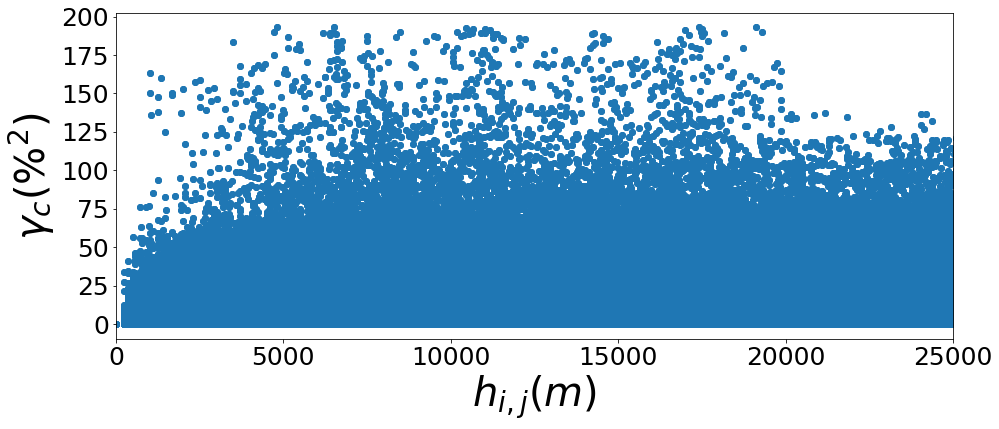

In [20]:
# PART A
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt

data = xr.open_dataset('/data/HW/HW4/HW4.nc', group='samples')

x = data['x'].values
y = data['y'].values
s = data['sand'].values

coords = np.column_stack([x, y])
print(coords.shape)
diff = coords[:, np.newaxis, :] - coords[np.newaxis, :, :] 
h = np.sqrt((diff**2).sum(axis=-1))   
gamma_c = (s[:, np.newaxis] - s[np.newaxis, :])**2 / 2

plt.figure(figsize=(15,6))

#Make the scatter plot
plt.scatter(h,gamma_c)

#Let's only consider points that are up to 25000 meters away from each other
plt.xlim([0,25000])

#Pretty up the plot
plt.xticks(fontsize=25)
plt.yticks(fontsize=25)
plt.xlabel(r'$h_{i,j} (m)$',fontsize=40)
plt.ylabel(r'$\gamma_c(\%^2)$',fontsize=40)
plt.show()

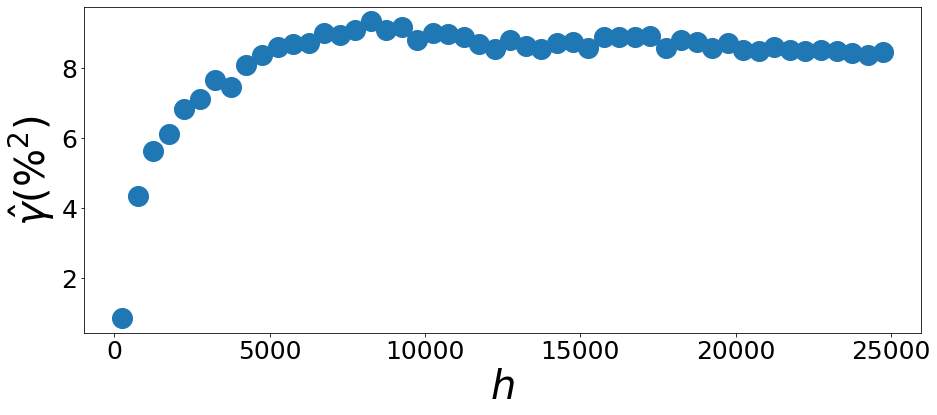

In [21]:
# PART B

#Define delta
delta = 500 #m

#Define bin edges
bin_edges = np.linspace(0,25000,25000/delta+1)

#Compute the center of each bin
hd = (bin_edges[1:] + bin_edges[0:-1])/2

#Compute sample semivariogram
gamma_s = []
for i in range(hd.size):
    if i == 0:m = (h >= bin_edges[i]) & (h < bin_edges[i+1])
    else:m = (h > bin_edges[i]) & (h <= bin_edges[i+1])
    tmp = np.mean(gamma_c[m])
    gamma_s.append(tmp)
gamma_s = np.array(gamma_s)

plt.figure(figsize=(15,6))
plt.plot(hd,gamma_s,'o',markersize=20)

#Pretty up the plot
plt.xticks(fontsize=25)
plt.yticks(fontsize=25)
plt.xlabel(r'$h$',fontsize=40)
plt.ylabel(r'$\hat{\gamma}(\%^2)$',fontsize=40)
plt.show()

sill (c): 8.72
range (tau): 1405.75
Exponential     sill c =     8.72   range a =   1405.8 m   R^2 = 0.9595
Spherical       sill c =     8.64   range a =   3297.8 m   R^2 = 0.8987
Bounded linear  sill c =     8.66   range a =   2757.1 m   R^2 = 0.8502


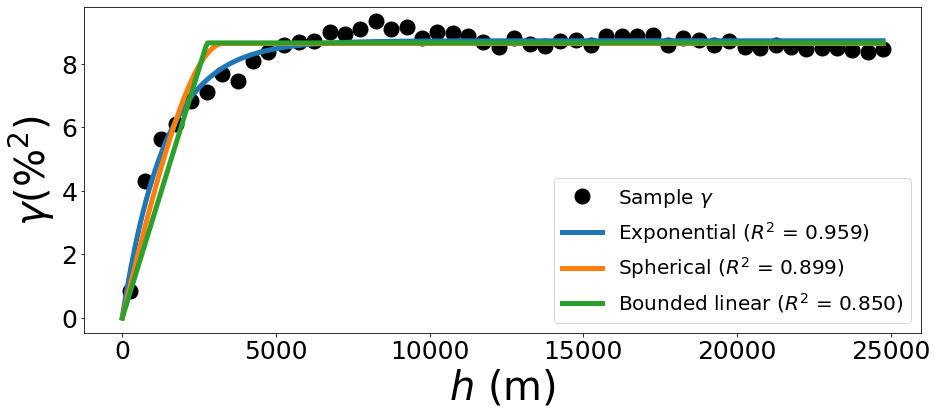

In [23]:
# PART C

import scipy.optimize

def exponential_semivariogram(h, c, a):
    return c * (1 - np.exp(-h / a))

def spherical_semivariogram(h, c, a):
    hr = np.minimum(h / a, 1)            # caps at 1 once h >= a
    return c * (1.5 * hr - 0.5 * hr**3)

def bounded_linear_semivariogram(h, c, a):
    return c * np.minimum(h / a, 1)      # rises linearly, flat at the sill after h = a

popt, pcov = scipy.optimize.curve_fit(exponential_semivariogram,hd,gamma_s,bounds=([0,100],[100,10000]))
print('sill (c): %.2f' % popt[0])
print('range (tau): %.2f' % popt[1])

def r_squared(obs, pred):
    ss_res = np.sum((obs - pred)**2)
    ss_tot = np.sum((obs - np.mean(obs))**2)
    return 1 - ss_res / ss_tot

# Drop any empty bins (np.mean of an empty selection gives NaN)
ok = ~np.isnan(gamma_s)
hd_fit, gs_fit = hd[ok], gamma_s[ok]

# Bounds from the data: sill between 0 and 2x the largest sample value,
# range between one bin width and the max lag
lower = [0, delta]
upper = [2 * np.nanmax(gamma_s), hd.max()]

models = {
    'Exponential': exponential_semivariogram,
    'Spherical': spherical_semivariogram,
    'Bounded linear': bounded_linear_semivariogram,
}

results = {}
for name, func in models.items():
    popt, pcov = scipy.optimize.curve_fit(func, hd_fit, gs_fit, bounds=(lower, upper))
    r2 = r_squared(gs_fit, func(hd_fit, *popt))
    results[name] = (popt, r2)
    print('%-15s sill c = %8.2f   range a = %8.1f m   R^2 = %.4f' % (name, popt[0], popt[1], r2))

# Plot all fits over the sample semivariogram
h_smooth = np.linspace(0, hd.max(), 500)

plt.figure(figsize=(15, 6))
plt.plot(hd, gamma_s, 'o', markersize=15, color='k', label=r'Sample $\gamma$')
for name, func in models.items():
    popt, r2 = results[name]
    plt.plot(h_smooth, func(h_smooth, *popt), lw=5, label='%s ($R^2$ = %.3f)' % (name, r2))

plt.xticks(fontsize=25)
plt.yticks(fontsize=25)
plt.xlabel(r'$h$ (m)', fontsize=40)
plt.ylabel(r'$\gamma(\%^2)$', fontsize=40)
plt.legend(fontsize=20)
plt.show()

# 3. Ordinary Kriging (25 pts)

Using the data in the samples group in '/data/HW/HW4/HW4.nc', and assumming an exponential semivariogram with a sill ($c$) of 10.0 $\%^2$, a nugget of 0, and a range ($a$) of 1500 m, do the following:

A. Use ordinary kriging to try to reproduce the original map of sand (as found in the original_data group in `/data/HW/HW4/HW4.nc`).

B. Plot the reproduced map and the original map. Compare the two via the $R^2$.

C. Compute the estimated mean squared error at each grid cell (kriging variance) and plot the map. Discuss the results. 

D. One of the largest limitations of Kriging is that the observation covariance matrix can become too large. Another more practical approach is to only use the closest $n$ points to each point to which we interpolate. Setting $n = 10$, perform this "localized" ordinary kriging and compare the results to those from part B. 

E. Repeat part D. However, this time set $n=1$. What other deterministic spatial interpolation method does this now mimic?

<xarray.Dataset>
Dimensions:  (x: 105, y: 133)
Coordinates:
  * x        (x) float64 -1.3e+04 -1.275e+04 -1.25e+04 ... 1.275e+04 1.3e+04
  * y        (y) float64 1.654e+04 1.629e+04 1.604e+04 ... -1.621e+04 -1.646e+04
Data variables:
    sand     (y, x) float64 ...
(133, 105) (133, 105) (133, 105)


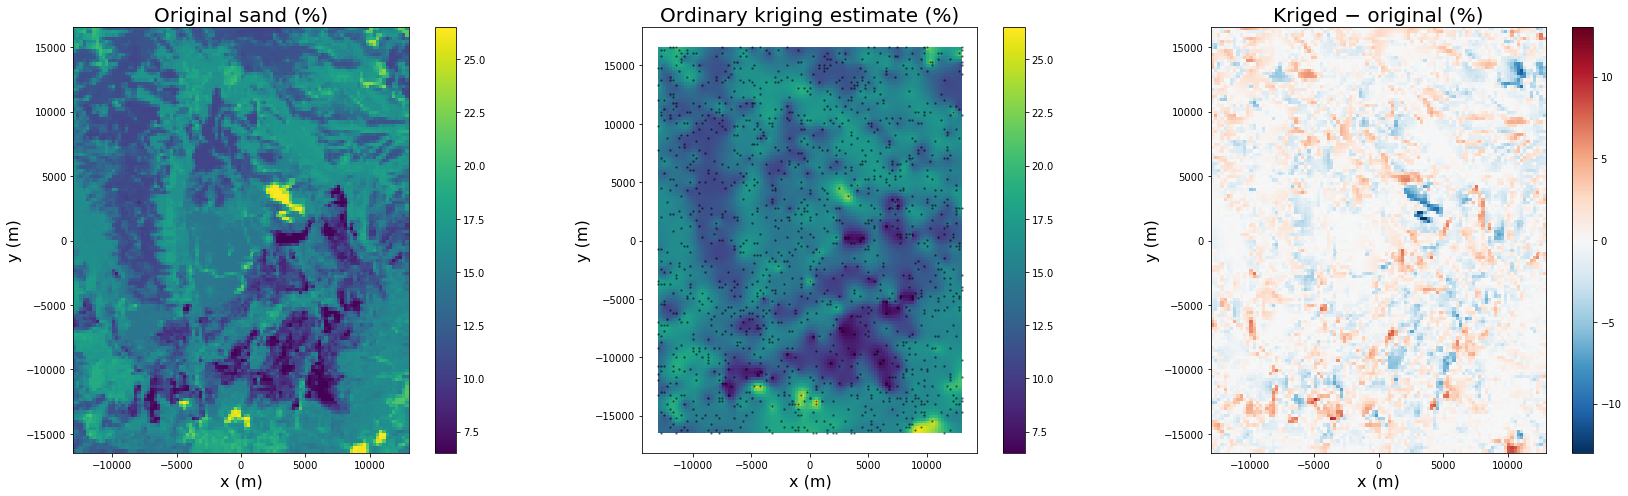

RMSE: 1.82 %   correlation: 0.784


In [25]:
# Part A

import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.distance import cdist
from scipy.linalg import lu_factor, lu_solve

path = '/data/HW/HW4/HW4.nc'
samples = xr.open_dataset(path, group='samples')
orig = xr.open_dataset(path, group='original_data')
print(orig)   # check variable names, dims, and grid size

# ---- Sample data ----
xs = samples['x'].values
ys = samples['y'].values
s = samples['sand'].values
pts = np.column_stack([xs, ys])
n = len(s)

# ---- Semivariogram (exponential, nugget = 0) ----
c = 10.0     # sill (%^2)
a = 1500.0   # range (m)

def gamma_exp(h):
    return c * (1 - np.exp(-h / a))

# ---- Ordinary kriging matrix (built and factored once) ----
#  [ Gamma  1 ] [ w  ]   [ gamma_0 ]
#  [ 1^T    0 ] [ mu ] = [    1    ]
K = np.ones((n + 1, n + 1))
K[:n, :n] = gamma_exp(cdist(pts, pts))
K[n, n] = 0.0
lu = lu_factor(K)

# ---- Target grid from the original map ----
sand_true = orig['sand']
truth = sand_true.values
xg = orig['x'].values
yg = orig['y'].values

if xg.ndim == 2:
    # x and y are already full 2D grids
    Xg, Yg = xg, yg
else:
    # x and y are 1D; match the grid to sand's dimension order
    if sand_true.dims[-1] == orig['x'].dims[0]:
        Xg, Yg = np.meshgrid(xg, yg)                   # sand is (y, x)
    else:
        Xg, Yg = np.meshgrid(xg, yg, indexing='ij')    # sand is (x, y)

print(truth.shape, Xg.shape, Yg.shape)   # these three should match
grid_pts = np.column_stack([Xg.ravel(), Yg.ravel()])
N = len(grid_pts)

# ---- Krige in chunks to limit memory use ----
est = np.empty(N)
krig_var = np.empty(N)
chunk = 5000

for start in range(0, N, chunk):
    g = grid_pts[start:start + chunk]
    rhs = np.ones((n + 1, len(g)))
    rhs[:n] = gamma_exp(cdist(pts, g))     # semivariance from each sample to each target
    sol = lu_solve(lu, rhs)
    w, mu = sol[:n], sol[n]
    est[start:start + chunk] = s @ w                           # kriged estimate
    krig_var[start:start + chunk] = np.sum(w * rhs[:n], axis=0) + mu   # kriging variance

sand_krig = est.reshape(Xg.shape)
sand_kvar = krig_var.reshape(Xg.shape)

# Keep the same no-data areas as the original map, if any
truth = sand_true.values
sand_krig[np.isnan(truth)] = np.nan
sand_kvar[np.isnan(truth)] = np.nan

vmin, vmax = np.nanmin(truth), np.nanmax(truth)

fig, axes = plt.subplots(1, 3, figsize=(24, 7))

im0 = axes[0].pcolormesh(Xg, Yg, truth, vmin=vmin, vmax=vmax, cmap='viridis', shading='auto')
axes[0].set_title('Original sand (%)', fontsize=20)
plt.colorbar(im0, ax=axes[0])

im1 = axes[1].pcolormesh(Xg, Yg, sand_krig, vmin=vmin, vmax=vmax, cmap='viridis', shading='auto')
axes[1].scatter(xs, ys, s=2, c='k', alpha=0.4)
axes[1].set_title('Ordinary kriging estimate (%)', fontsize=20)
plt.colorbar(im1, ax=axes[1])

err = sand_krig - truth
lim = np.nanmax(np.abs(err))
im2 = axes[2].pcolormesh(Xg, Yg, err, vmin=-lim, vmax=lim, cmap='RdBu_r', shading='auto')
axes[2].set_title('Kriged − original (%)', fontsize=20)
plt.colorbar(im2, ax=axes[2])

for ax in axes:
    ax.set_xlabel('x (m)', fontsize=16)
    ax.set_ylabel('y (m)', fontsize=16)
    ax.set_aspect('equal')
plt.tight_layout()
plt.show()

valid = ~np.isnan(truth)
rmse = np.sqrt(np.mean(err[valid]**2))
r = np.corrcoef(truth[valid], sand_krig[valid])[0, 1]
print('RMSE: %.2f %%   correlation: %.3f' % (rmse, r))

R^2 = 0.611


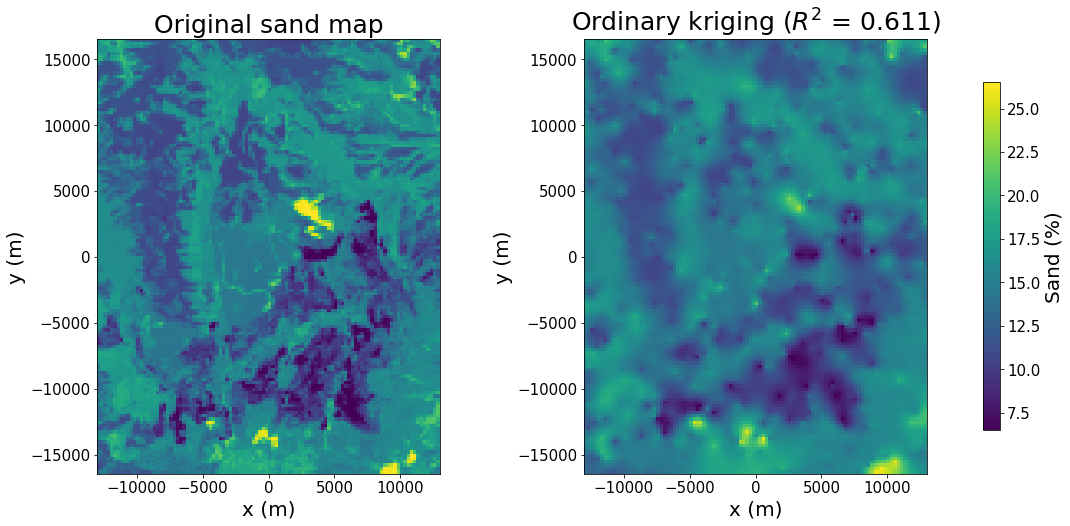

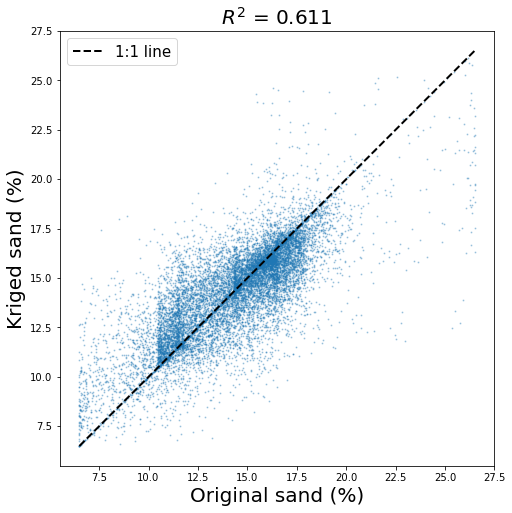

In [26]:
# PART B

# ---- R^2 between original and kriged maps ----
valid = ~np.isnan(truth) & ~np.isnan(sand_krig)
obs = truth[valid]
pred = sand_krig[valid]

ss_res = np.sum((obs - pred)**2)
ss_tot = np.sum((obs - np.mean(obs))**2)
r2 = 1 - ss_res / ss_tot
print('R^2 = %.3f' % r2)

# ---- Side-by-side maps on a shared color scale ----
vmin, vmax = np.nanmin(truth), np.nanmax(truth)

fig, axes = plt.subplots(1, 2, figsize=(20, 8))

im0 = axes[0].pcolormesh(Xg, Yg, truth, vmin=vmin, vmax=vmax, cmap='viridis', shading='auto')
axes[0].set_title('Original sand map', fontsize=25)

im1 = axes[1].pcolormesh(Xg, Yg, sand_krig, vmin=vmin, vmax=vmax, cmap='viridis', shading='auto')
axes[1].set_title('Ordinary kriging ($R^2$ = %.3f)' % r2, fontsize=25)

for ax in axes:
    ax.set_xlabel('x (m)', fontsize=20)
    ax.set_ylabel('y (m)', fontsize=20)
    ax.tick_params(labelsize=15)
    ax.set_aspect('equal')

cbar = fig.colorbar(im1, ax=axes, shrink=0.8)
cbar.set_label('Sand (%)', fontsize=20)
cbar.ax.tick_params(labelsize=15)
plt.show()

# ---- Scatter of kriged vs. original values ----
plt.figure(figsize=(8, 8))
plt.scatter(obs, pred, s=1, alpha=0.3)
plt.plot([vmin, vmax], [vmin, vmax], 'k--', lw=2, label='1:1 line')
plt.xlabel('Original sand (%)', fontsize=20)
plt.ylabel('Kriged sand (%)', fontsize=20)
plt.title('$R^2$ = %.3f' % r2, fontsize=20)
plt.legend(fontsize=15)
plt.gca().set_aspect('equal')
plt.show()

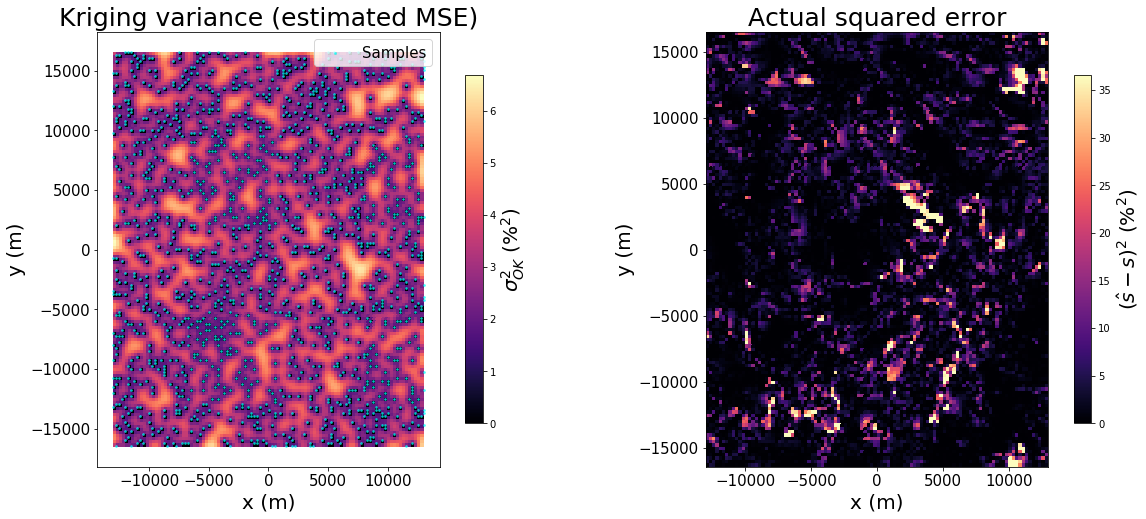

Kriging variance: min -0.00, mean 2.76, max 7.18 %^2
Actual MSE over the map: 3.30 %^2


In [27]:
# PART C

fig, axes = plt.subplots(1, 2, figsize=(20, 8))

# Kriging variance (estimated MSE)
im0 = axes[0].pcolormesh(Xg, Yg, sand_kvar, cmap='magma', shading='auto')
axes[0].scatter(xs, ys, s=3, c='cyan', alpha=0.6, label='Samples')
axes[0].set_title('Kriging variance (estimated MSE)', fontsize=25)
cb0 = fig.colorbar(im0, ax=axes[0], shrink=0.8)
cb0.set_label(r'$\sigma^2_{OK}$ ($\%^2$)', fontsize=20)
axes[0].legend(fontsize=15, loc='upper right')

# Actual squared error, for comparison
sq_err = (sand_krig - truth)**2
im1 = axes[1].pcolormesh(Xg, Yg, sq_err, cmap='magma', shading='auto',
                         vmax=np.nanpercentile(sq_err, 99))
axes[1].set_title('Actual squared error', fontsize=25)
cb1 = fig.colorbar(im1, ax=axes[1], shrink=0.8)
cb1.set_label(r'$(\hat{s} - s)^2$ ($\%^2$)', fontsize=20)

for ax in axes:
    ax.set_xlabel('x (m)', fontsize=20)
    ax.set_ylabel('y (m)', fontsize=20)
    ax.tick_params(labelsize=15)
    ax.set_aspect('equal')
plt.show()

print('Kriging variance: min %.2f, mean %.2f, max %.2f %%^2'
      % (np.nanmin(sand_kvar), np.nanmean(sand_kvar), np.nanmax(sand_kvar)))
print('Actual MSE over the map: %.2f %%^2' % np.nanmean(sq_err))

The MSE is 0 whereever a sample was taken, and highest in areas far away from any sample.

Localized kriging time: 0.1 s
R^2 global kriging:     0.611
R^2 localized (n=10):   0.611
Max |local - global|:   1.73 %


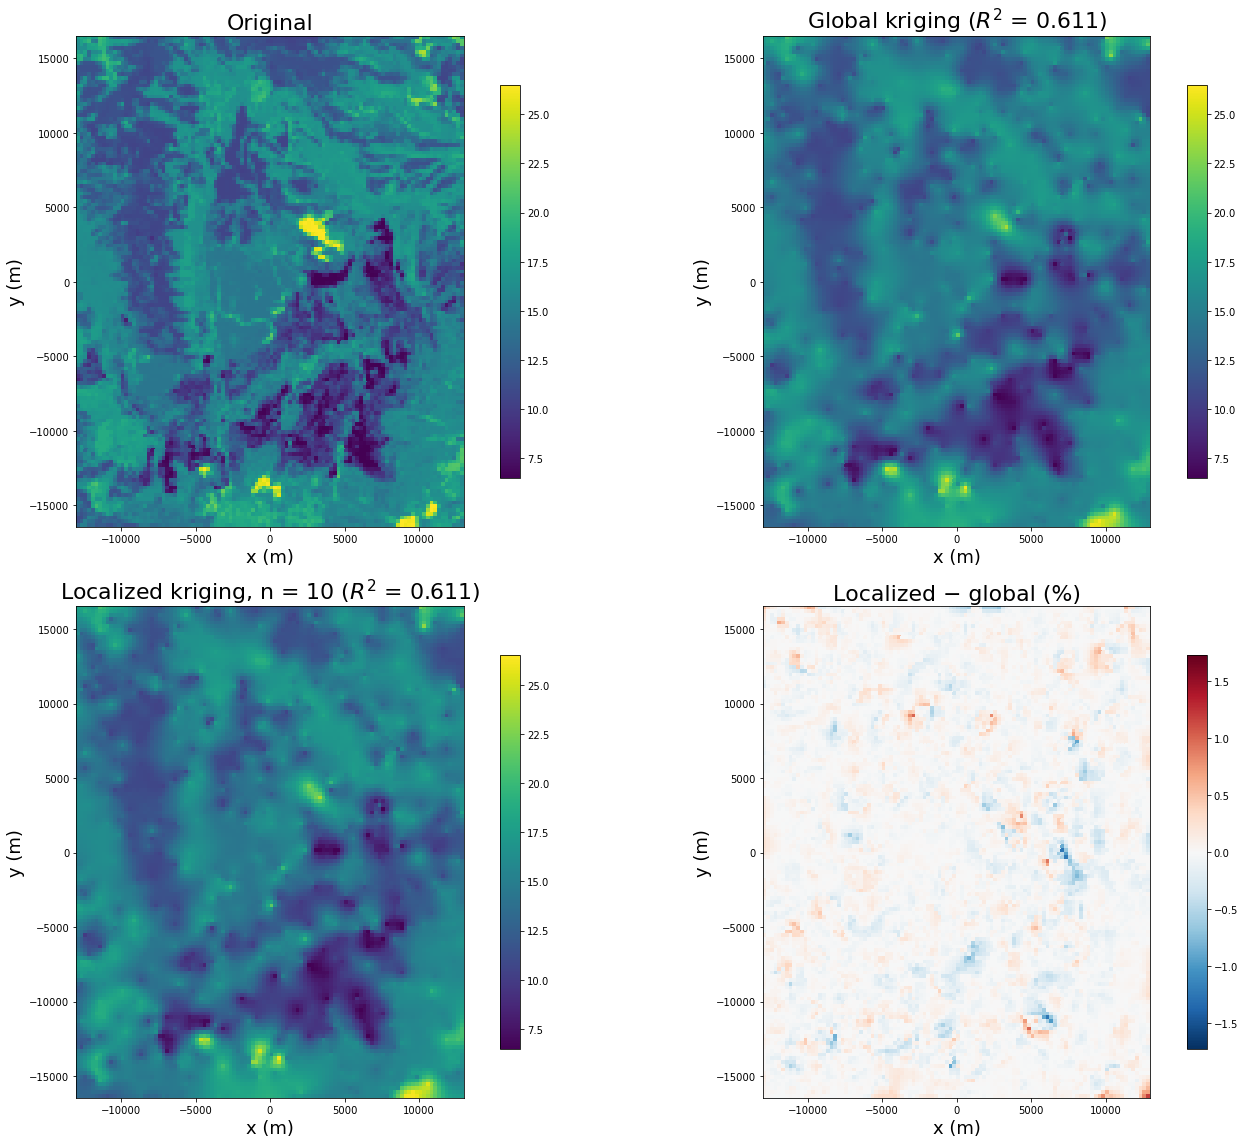

In [28]:
# PART D
import time
from scipy.spatial import cKDTree

n_local = 10
tree = cKDTree(pts)

est_loc = np.empty(N)
var_loc = np.empty(N)
chunk = 20000

t0 = time.time()
for start in range(0, N, chunk):
    g = grid_pts[start:start + chunk]
    m = len(g)

    # 10 nearest samples to each grid point: distances (m, 10), indices (m, 10)
    d0, idx = tree.query(g, k=n_local)

    # Distances among each point's neighbors: (m, 10, 10)
    nb = pts[idx]                                        # (m, 10, 2)
    dnn = np.sqrt(((nb[:, :, None, :] - nb[:, None, :, :])**2).sum(axis=-1))

    # Build m separate ordinary kriging systems: (m, 11, 11)
    K = np.ones((m, n_local + 1, n_local + 1))
    K[:, :n_local, :n_local] = gamma_exp(dnn)
    K[:, n_local, n_local] = 0.0

    rhs = np.ones((m, n_local + 1, 1))
    rhs[:, :n_local, 0] = gamma_exp(d0)

    sol = np.linalg.solve(K, rhs)[:, :, 0]               # (m, 11)
    w, mu = sol[:, :n_local], sol[:, n_local]

    est_loc[start:start + chunk] = np.sum(w * s[idx], axis=1)
    var_loc[start:start + chunk] = np.sum(w * rhs[:, :n_local, 0], axis=1) + mu
print('Localized kriging time: %.1f s' % (time.time() - t0))

sand_loc = est_loc.reshape(Xg.shape)
sand_loc_var = var_loc.reshape(Xg.shape)
sand_loc[np.isnan(truth)] = np.nan
sand_loc_var[np.isnan(truth)] = np.nan

def r_squared(obs, pred):
    ok = ~np.isnan(obs) & ~np.isnan(pred)
    return 1 - np.sum((obs[ok] - pred[ok])**2) / np.sum((obs[ok] - np.mean(obs[ok]))**2)

r2_global = r_squared(truth, sand_krig)
r2_local = r_squared(truth, sand_loc)
print('R^2 global kriging:     %.3f' % r2_global)
print('R^2 localized (n=10):   %.3f' % r2_local)
print('Max |local - global|:   %.2f %%' % np.nanmax(np.abs(sand_loc - sand_krig)))

vmin, vmax = np.nanmin(truth), np.nanmax(truth)
fig, axes = plt.subplots(2, 2, figsize=(20, 16))

panels = [
    (truth, 'Original', 'viridis', vmin, vmax),
    (sand_krig, 'Global kriging ($R^2$ = %.3f)' % r2_global, 'viridis', vmin, vmax),
    (sand_loc, 'Localized kriging, n = 10 ($R^2$ = %.3f)' % r2_local, 'viridis', vmin, vmax),
]
diff = sand_loc - sand_krig
lim = np.nanmax(np.abs(diff))
panels.append((diff, 'Localized − global (%)', 'RdBu_r', -lim, lim))

for ax, (field, title, cmap, lo, hi) in zip(axes.ravel(), panels):
    im = ax.pcolormesh(Xg, Yg, field, cmap=cmap, vmin=lo, vmax=hi, shading='auto')
    ax.set_title(title, fontsize=22)
    ax.set_xlabel('x (m)', fontsize=18)
    ax.set_ylabel('y (m)', fontsize=18)
    ax.set_aspect('equal')
    fig.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout()
plt.show()

The n=10 map appears to perform quite similarly to the globally kriged map.

Identical to nearest neighbor: True
R^2 global kriging:     0.611
R^2 localized, n = 10:  0.611
R^2 localized, n = 1:   0.409


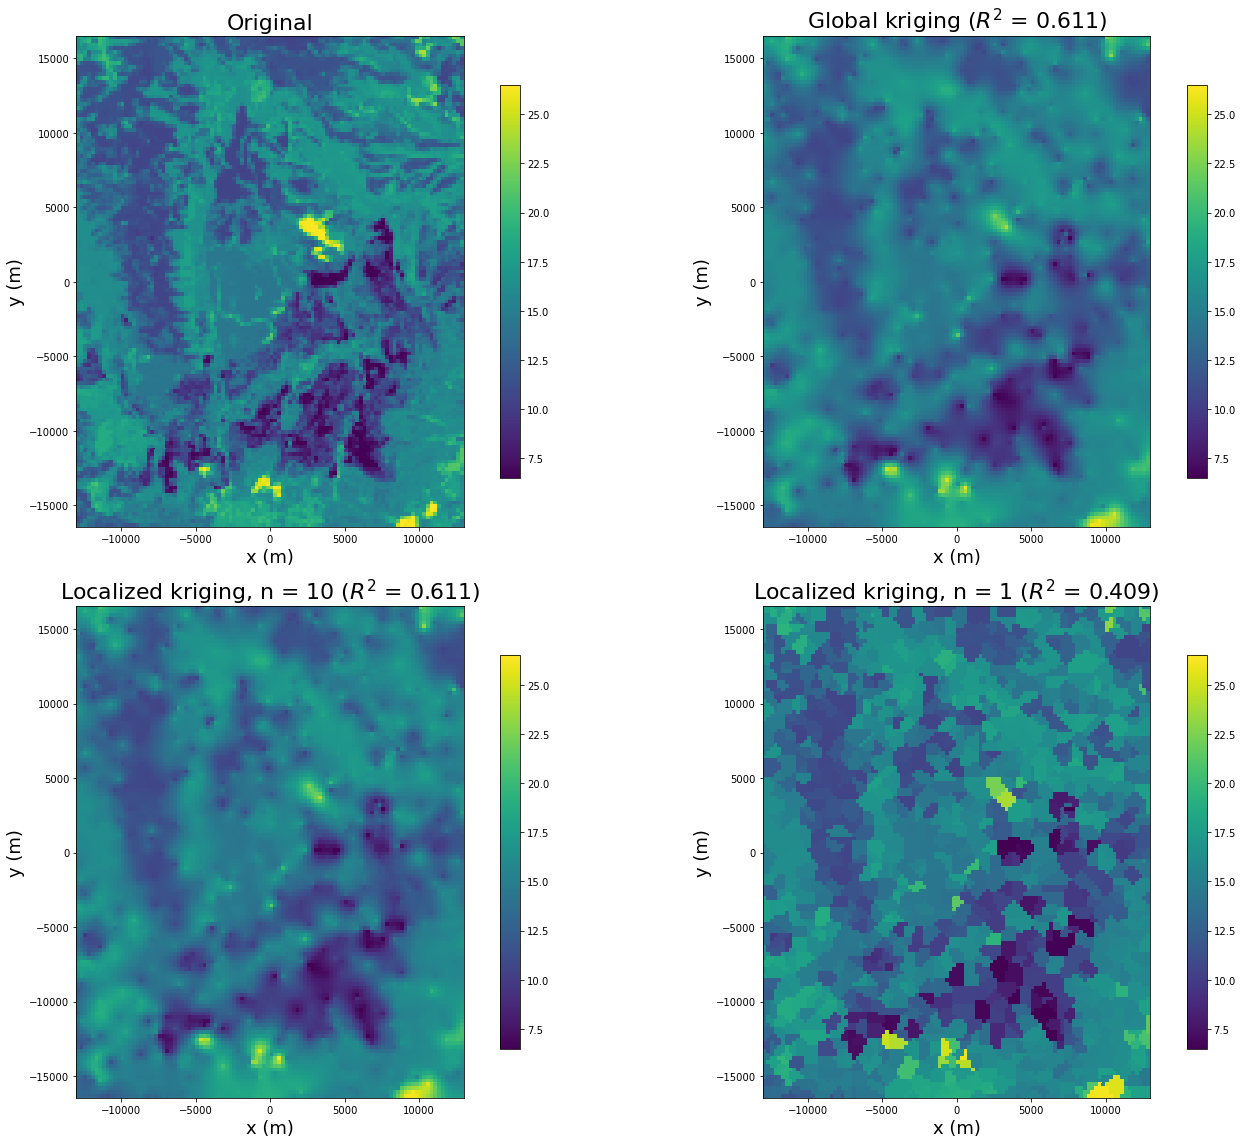

In [29]:
# PART E

def local_ok(n_local, chunk=20000):
    est = np.empty(N)
    var = np.empty(N)
    for start in range(0, N, chunk):
        g = grid_pts[start:start + chunk]
        m = len(g)

        d0, idx = tree.query(g, k=n_local)
        d0 = d0.reshape(m, n_local)      # keep 2D shape even when k = 1
        idx = idx.reshape(m, n_local)

        nb = pts[idx]
        dnn = np.sqrt(((nb[:, :, None, :] - nb[:, None, :, :])**2).sum(axis=-1))

        K = np.ones((m, n_local + 1, n_local + 1))
        K[:, :n_local, :n_local] = gamma_exp(dnn)
        K[:, n_local, n_local] = 0.0

        rhs = np.ones((m, n_local + 1, 1))
        rhs[:, :n_local, 0] = gamma_exp(d0)

        sol = np.linalg.solve(K, rhs)[:, :, 0]
        w, mu = sol[:, :n_local], sol[:, n_local]

        est[start:start + chunk] = np.sum(w * s[idx], axis=1)
        var[start:start + chunk] = np.sum(w * rhs[:, :n_local, 0], axis=1) + mu

    est = est.reshape(Xg.shape)
    var = var.reshape(Xg.shape)
    est[np.isnan(truth)] = np.nan
    var[np.isnan(truth)] = np.nan
    return est, var

sand_n1, var_n1 = local_ok(1)

# Check: is this identical to plain nearest-neighbor interpolation?
_, nn_idx = tree.query(grid_pts, k=1)
sand_nn = s[nn_idx].reshape(Xg.shape)
sand_nn[np.isnan(truth)] = np.nan
print('Identical to nearest neighbor:', np.allclose(sand_n1, sand_nn, equal_nan=True))

r2_n1 = r_squared(truth, sand_n1)
print('R^2 global kriging:     %.3f' % r2_global)
print('R^2 localized, n = 10:  %.3f' % r2_local)
print('R^2 localized, n = 1:   %.3f' % r2_n1)

fig, axes = plt.subplots(2, 2, figsize=(20, 16))
panels = [
    (truth, 'Original'),
    (sand_krig, 'Global kriging ($R^2$ = %.3f)' % r2_global),
    (sand_loc, 'Localized kriging, n = 10 ($R^2$ = %.3f)' % r2_local),
    (sand_n1, 'Localized kriging, n = 1 ($R^2$ = %.3f)' % r2_n1),
]
for ax, (field, title) in zip(axes.ravel(), panels):
    im = ax.pcolormesh(Xg, Yg, field, cmap='viridis', vmin=vmin, vmax=vmax, shading='auto')
    ax.set_title(title, fontsize=22)
    ax.set_xlabel('x (m)', fontsize=18)
    ax.set_ylabel('y (m)', fontsize=18)
    ax.set_aspect('equal')
    fig.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout()
plt.show()

This looks a lot like nearest neighbor interpolation.

# 4. Calculate upslope drainage area (25 pts)

Using the elevation data found in `/data/HW/HW4/mtdiablo_dem_sf.tif`, show that the upslope drainage area flowing out of the grid cell point i = 582 and j = 779 is 12,856,300 $m^2$. You will need to write up your own recursive algorithm to estimate upslope drainage area for this problem. You will want to use the d8 flow direction approach. In other words, assume that if a ball is dropped on a given grid cell it will follow the path of steepest descent (i.e., the highest slope) to one (and only one) adjacent cell. Note that the pixel size is 10 meters by 10 meters. Furthermore, you may assume that this data has already been sink-filled.

DEM shape: (760, 780)   pixel size: 10.0 10.0
Upslope cells: 128563
Upslope drainage area: 12,856,300 m^2


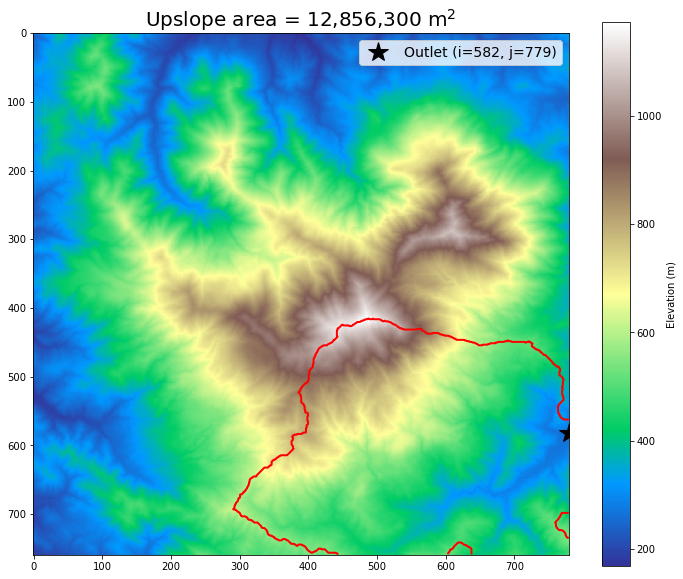

In [30]:
import numpy as np
import matplotlib.pyplot as plt

path = '/data/HW/HW4/mtdiablo_dem_sf.tif'

try:
    import rasterio
    with rasterio.open(path) as src:
        z = src.read(1).astype(float)
        nodata = src.nodata
        dx, dy = src.res
except ImportError:
    from osgeo import gdal
    ds = gdal.Open(path)
    band = ds.GetRasterBand(1)
    z = band.ReadAsArray().astype(float)
    nodata = band.GetNoDataValue()
    gt = ds.GetGeoTransform()
    dx, dy = gt[1], abs(gt[5])

if nodata is not None:
    z[z == nodata] = np.nan

print('DEM shape:', z.shape, '  pixel size:', dx, dy)

# Neighbor offsets (row, col) and distances
offsets = [(-1, -1), (-1, 0), (-1, 1),
           ( 0, -1),          ( 0, 1),
           ( 1, -1), ( 1, 0), ( 1, 1)]
cell = 10.0
dists = np.array([np.hypot(di, dj) * cell for di, dj in offsets])

nr, nc = z.shape
zp = np.pad(z, 1, mode='constant', constant_values=np.nan)

slopes = np.full((8, nr, nc), -np.inf)
for k, (di, dj) in enumerate(offsets):
    zn = zp[1 + di:1 + di + nr, 1 + dj:1 + dj + nc]
    sk = (z - zn) / dists[k]
    sk[np.isnan(sk)] = -np.inf          # off-grid or nodata neighbors can't receive flow
    slopes[k] = sk

fdir = np.argmax(slopes, axis=0)        # index of steepest neighbor
fdir[np.max(slopes, axis=0) <= 0] = -1  # no downhill neighbor

# For each direction k, the index of the opposite direction
opposite = [offsets.index((-di, -dj)) for di, dj in offsets]

def upslope_cells(i, j, mask):
    """Number of cells draining through (i, j), including (i, j) itself."""
    mask[i, j] = True
    count = 1
    for k, (di, dj) in enumerate(offsets):
        ni, nj = i + di, j + dj
        if 0 <= ni < nr and 0 <= nj < nc and fdir[ni, nj] == opposite[k]:
            count += upslope_cells(ni, nj, mask)
    return count

import sys
import threading

sys.setrecursionlimit(10**6)
threading.stack_size(2**28)   # 256 MB stack for the worker thread

i0, j0 = 582, 779
basin = np.zeros_like(z, dtype=bool)
result = {}

def run():
    result['cells'] = upslope_cells(i0, j0, basin)

t = threading.Thread(target=run)
t.start()
t.join()

n_cells = result['cells']
area = n_cells * dx * dy
print('Upslope cells: %d' % n_cells)
print('Upslope drainage area: {:,.0f} m^2'.format(area))

plt.figure(figsize=(12, 10))
plt.imshow(z, cmap='terrain')
plt.colorbar(label='Elevation (m)')
plt.contour(basin, levels=[0.5], colors='red', linewidths=2)
plt.plot(j0, i0, 'k*', markersize=20, label='Outlet (i=%d, j=%d)' % (i0, j0))
plt.title('Upslope area = {:,.0f} m$^2$'.format(area), fontsize=20)
plt.legend(fontsize=14)
plt.show()